# Klike Challenge — Part 3: Recommendations Engine

**Input:** one campaign (a row of the dataset, or a new campaign as a dict).
**Output:** creative changes ranked by estimated impact, each quantified with a 95% interval and
explained with evidence from comparable campaigns.

The engine lives in `klike/recommender.py`; this notebook shows how it reasons and what it
produces. The same engine runs from the command line:

```
python recommend.py KLK-0116            # one campaign
python recommend.py --file new.json     # a campaign that is not in the dataset
python recommend.py --portfolio         # where the biggest opportunities are
```

## How a recommendation is built

| Step | What happens | Where the numbers come from |
|---|---|---|
| 1. Candidates | Every creative lever the campaign could change: add hook / face / CTA / subtitles, change text density, re-cut to another format **that the platform actually runs** (≥15 campaigns), make the audio voice-led, move duration toward the platform's CTR optimum | the campaign's own attributes |
| 2. Score impact | Predicted Klike Score after the change minus before | **Part 2 creative model**, with 300 bootstrap refits for the 95% interval |
| 3. Metric impact | Relative change in CTR, engagement rate and conversions at the same reach, **on this campaign's platform** | ridge regressions on log-metrics with lever × platform terms, adjusted for category, objective, age and retargeting (below) |
| 4. Guardrails | Keep a change only if it clears zero on the score or a metric; **never** if it is expected to cost ≥10% (or significantly) on the metric the campaign's objective pays for; disclose any other significant trade-off | intervals from steps 2–3 |
| 5. Rank | By estimated Klike Score gain (duration, which has no score effect, is ranked on CTR) | |
| 6. Explain | Peer evidence: share of top- vs bottom-quartile creatives on the same platform (and category, when ≥50 peers) that use the proposed value | the dataset |

Three deliberate exclusions: **retargeting** is never recommended (Part 1: it moves conversions, not
creative quality, and it is an audience decision, not a creative one); **ROAS** is never promised
(no creative lever moves it); and **formats a platform does not run** are never proposed (there is
no horizontal video on TikTok to learn from).

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from klike.data import load_clean
from klike.model import LABELS
from klike.recommender import RecommendationEngine

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)

df = load_clean()
start = time.time()
engine = RecommendationEngine(n_bootstrap=300).fit(df)
print(f"engine fitted in {time.time() - start:.1f}s")

engine fitted in 3.7s


In [2]:
# Chart style, same as in 01_eda: thin marks, light grid, a colourblind-safe palette.
# Platforms always keep the same colour and are labelled directly on the chart.
SURFACE, INK, INK_SOFT, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
PLATFORM_COLOURS = {"TikTok": BLUE, "Meta": ORANGE, "LinkedIn": AQUA}


def new_chart(size=(9, 4.2), ncols=1, sharey=False):
    figure, axes = plt.subplots(1, ncols, figsize=size, sharey=sharey)
    figure.patch.set_facecolor(SURFACE)
    for ax in (axes if ncols > 1 else [axes]):
        ax.set_facecolor(SURFACE)
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.tick_params(colors=MUTED, length=0, labelsize=9)
        for label in ax.get_xticklabels() + ax.get_yticklabels():
            label.set_color(INK_SOFT)
        ax.set_axisbelow(True)
    return figure, axes


def finish(figure, ax, title, subtitle, note, name=None):
    ax.set_title(title, color=INK, fontsize=13, fontweight="bold", loc="left", pad=26)
    ax.annotate(subtitle, xy=(0, 1), xytext=(0, 12), xycoords="axes fraction",
                textcoords="offset points", color=INK_SOFT, fontsize=9.5, va="bottom")
    figure.text(0.01, 0.005, note, color=MUTED, fontsize=7.5, va="bottom")
    figure.tight_layout(rect=(0, 0.03, 1, 1))
    if name:  # saved for the README
        Path("figures").mkdir(exist_ok=True)
        figure.savefig(f"figures/{name}.png", dpi=150, facecolor=SURFACE)
    plt.show()

---
# 1. What works where — the contextual layer

The challenge's central question for this part: *what works on TikTok may not work on LinkedIn.*
The lift models answer it by giving every lever a pooled effect **plus** a platform-specific
deviation. Ridge shrinks the deviations toward zero, so a platform only gets its own answer when its
data insists — important with only 83 LinkedIn campaigns.

The table below asks each model the same questions on each platform.

In [3]:
REFERENCE = dict(category="E-commerce", objective="conversions", target_audience_age="25-34",
                 is_retargeting=False, video_duration_s=45.0, has_subtitle=False, has_cta=False,
                 has_hook=False, has_face=False, text_density="high", music_voice_ratio=0.6)
NATIVE = {"TikTok": ("quadrado", "vertical"), "Meta": ("horizontal", "quadrado"), "LinkedIn": ("vertical", "horizontal")}
CHANGES = [
    ("Hook in first 3s", {"has_hook": True}),
    ("Human face", {"has_face": True}),
    ("Call to action", {"has_cta": True}),
    ("Subtitles", {"has_subtitle": True}),
    ("Text high → medium", {"text_density": "medium"}),
    ("Audio voice-led (0.6 → 0.2)", {"music_voice_ratio": 0.2}),
    ("Native format", "native"),
    ("Duration 45s → 15s", {"video_duration_s": 15.0}),
]

rows = []
for platform, (other_format, native_format) in NATIVE.items():
    current = pd.DataFrame([{**REFERENCE, "platform": platform, "format": other_format}])
    for name, change in CHANGES:
        change = {"format": native_format} if change == "native" else change
        changed = current.assign(**change)
        score = engine.score_effect.effect(current, changed)[0]
        record = {"platform": platform, "change": name, "score": score[0], "score_sig": score[1] > 0 or score[2] < 0}
        for metric, effect in engine.metric_effects.items():
            estimate, low, high = effect.effect(current, changed)[0]
            record[metric] = estimate
            record[f"{metric}_sig"] = low > 0 or high < 0
        rows.append(record)
lifts = pd.DataFrame(rows)


def show(value, significant, percent=True):
    text = f"{value:+.0%}" if percent else f"{value:+.1f}"
    return text if significant else f"({text})"


table = pd.DataFrame({
    (p, m): [show(r[m if m != "pts" else "score"], r[f"{m}_sig" if m != "pts" else "score_sig"], m != "pts")
             for _, r in lifts[lifts.platform == p].iterrows()]
    for p in NATIVE for m in ["pts", "ctr", "conversions"]
}, index=[name for name, _ in CHANGES])
print("Klike points and relative lifts per platform · (parentheses) = 95% interval crosses zero\n")
table

Klike points and relative lifts per platform · (parentheses) = 95% interval crosses zero



TikTok                        Meta                     LinkedIn                    
                                pts     ctr conversions     pts     ctr conversions      pts     ctr conversions
Hook in first 3s              +17.1    +41%        +64%   +17.1    +34%        +35%    +17.1    +45%        +71%
Human face                    +11.8    +24%        +44%   +11.8  (+13%)      (+18%)    +11.8    +18%      (+33%)
Call to action                 +8.1  (+10%)       (+8%)    +8.1   (+6%)      (+10%)     +8.1   (+7%)       (-3%)
Subtitles                      +8.3  (+13%)      (+14%)    +8.3  (+10%)      (+13%)     +8.3   (-5%)      (-11%)
Text high → medium            +13.5  (+16%)      (+33%)   +13.5    +32%        +58%    +13.5   (+8%)      (+22%)
Audio voice-led (0.6 → 0.2)    +1.9   (+1%)      (+11%)    +1.9   (-3%)       (-4%)     +1.9   (+0%)       (+2%)
Native format                  +3.4  (-15%)      (-27%)    +5.5   (+2%)      (+23%)     +8.3  (+11%)      (+26%)
Duration 45s → 15s           (+0.5)  (+29%)      (+58%)  (+0.5)    +21%      (+11%)   (+0.5)  (-14%)      (-18%)

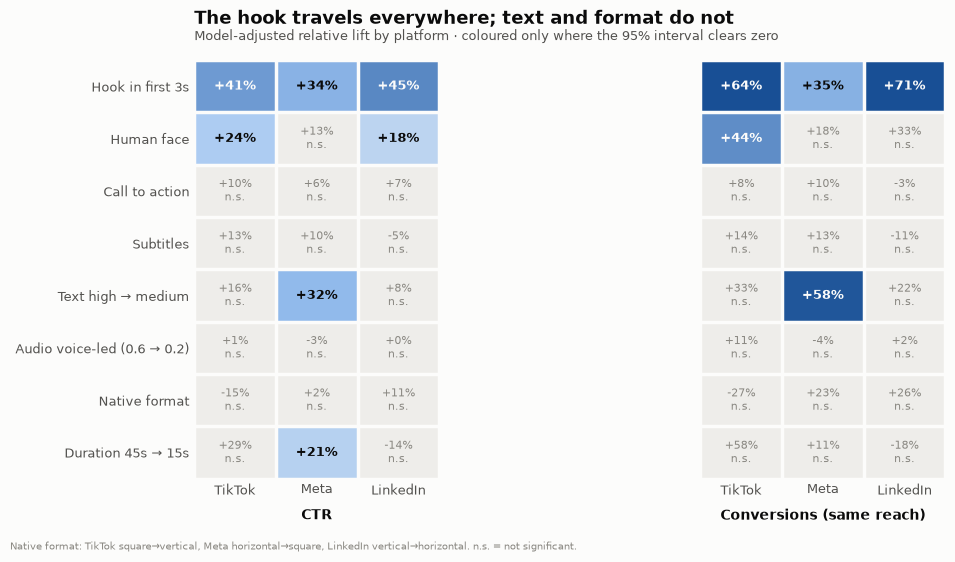

In [4]:
# CHART 1 - diverging grid: where each lever helps CTR, by platform. Colour only where the interval clears zero.
grid = lifts.pivot(index="change", columns="platform", values="ctr").reindex(index=[n for n, _ in CHANGES], columns=list(NATIVE))
significant = lifts.pivot(index="change", columns="platform", values="ctr_sig").reindex(index=grid.index, columns=grid.columns)
conversions = lifts.pivot(index="change", columns="platform", values="conversions").reindex(index=grid.index, columns=grid.columns)
conversions_sig = lifts.pivot(index="change", columns="platform", values="conversions_sig").reindex(index=grid.index, columns=grid.columns)

DIVERGING = LinearSegmentedColormap.from_list("div", ["#c1272d", "#e8a39d", "#efeeea", "#9ec5f4", "#184f95"])
limit = 0.6
figure, axes = new_chart((9.6, 5.6), ncols=2)
for ax, values, sig, title in [(axes[0], grid, significant, "CTR"), (axes[1], conversions, conversions_sig, "Conversions (same reach)")]:
    shown = values.where(sig, 0.0)
    ax.imshow(shown.to_numpy(dtype=float), cmap=DIVERGING, vmin=-limit, vmax=limit, aspect="auto")
    ax.set_xticks(range(values.shape[1]), values.columns)
    ax.set_yticks(range(values.shape[0]), values.index)
    ax.set_xticks(np.arange(-0.5, values.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, values.shape[0], 1), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2.5)
    ax.tick_params(which="minor", length=0)
    ax.set_xlabel(title, color=INK, fontsize=10, fontweight="bold", labelpad=8)
    if ax is axes[1]:
        ax.set_yticklabels([])
    for r in range(values.shape[0]):
        for c in range(values.shape[1]):
            value, is_sig = values.iat[r, c], bool(sig.iat[r, c])
            strong = is_sig and abs(value) > 0.35
            ax.text(c, r, f"{value:+.0%}" if is_sig else f"{value:+.0%}\nn.s.", ha="center", va="center",
                    fontsize=9.5 if is_sig else 8, fontweight="bold" if is_sig else "normal",
                    color=SURFACE if strong else (INK if is_sig else MUTED))
finish(figure, axes[0],
       "The hook travels everywhere; text and format do not",
       "Model-adjusted relative lift by platform · coloured only where the 95% interval clears zero",
       "Native format: TikTok square→vertical, Meta horizontal→square, LinkedIn vertical→horizontal. n.s. = not significant.",
       name="03_lifts_by_platform")

What the contextual layer adds, in plain terms:

- **The hook is the universal lever** — it lifts CTR and conversions on all three platforms.
- **A face pays off most on TikTok** (biggest CTR and conversion lifts) and least clearly on Meta.
- **Cutting heavy text is a Meta story for CTR and conversions.** On TikTok and LinkedIn it lifts the
  *score* just as much, but the click-through gain is not distinguishable from zero.
- **Native format is not free.** On TikTok, moving from square to vertical lifts the score (+3.4) and
  engagement, but its estimated effect on conversions is −27% (the interval only just reaches zero).
  This is where the engine's objective guardrail matters (§3).
- **Duration only matters for CTR on Meta**, where shorter is better; on LinkedIn shorter is, if
  anything, worse — a recommendation like "cut it to 15s" would be wrong there.

---
# 2. The engine on real campaigns

Four cases across the range: the worst creative in the dataset, a typical one, the best one, and a
campaign that is not in the dataset at all.

In [5]:
print(engine.recommend(df[df["campaign_id"] == "KLK-0116"]))

Campaign KLK-0116 · LinkedIn · Lead Gen · engagement · age 35-44
Klike Score 10.4  (creative model expects 15.6; potential with the changes below ≈ 77.5)

1. Add a hook in the first 3 seconds: Klike Score +17.1 pts (95% CI +15.7 to +18.4). On this platform it is associated with +45% CTR, +7% engagement rate, +71% conversions at the same reach (model-adjusted). 86% of top-quartile LinkedIn creatives open with a hook, vs 19% of the bottom quartile (n=83).

2. Change on-screen text from high to medium: Klike Score +13.5 pts (95% CI +11.4 to +15.4). 62% of top-quartile LinkedIn creatives use medium on-screen text, vs 29% of the bottom quartile (n=83).

3. Show a human face on screen: Klike Score +11.8 pts (95% CI +10.6 to +13.1). On this platform it is associated with +18% CTR (model-adjusted). 86% of top-quartile LinkedIn creatives show a face, vs 33% of the bottom quartile (n=83).

4. Add subtitles: Klike Score +8.3 pts (95% CI +7.0 to +9.7). 72% of top-quartile LinkedIn creatives are su

The worst creative in the dataset (it was one of the 16 targets Excel corrupted — dropping those rows
would have hidden exactly the campaign that most needs help). Six confident changes, led by the three
biggest levers. Every number is specific to LinkedIn: the format recommendation is *horizontal*, the
opposite of what TikTok would get.

In [6]:
print(engine.recommend(df[df["campaign_id"] == "KLK-0042"]))

Campaign KLK-0042 · Meta · App Install · app_install · age 25-34
Klike Score 51.0  (creative model expects 49.4; potential with the changes below ≈ 89.3)

1. Add a hook in the first 3 seconds: Klike Score +17.1 pts (95% CI +15.7 to +18.4). On this platform it is associated with +34% CTR, +10% engagement rate, +35% conversions at the same reach (model-adjusted). 93% of top-quartile Meta creatives open with a hook, vs 18% of the bottom quartile (n=241).

2. Show a human face on screen: Klike Score +11.8 pts (95% CI +10.6 to +13.1). On this platform it is associated with +10% engagement rate (model-adjusted). 77% of top-quartile Meta creatives show a face, vs 24% of the bottom quartile (n=241).

3. Add an explicit call to action: Klike Score +8.1 pts (95% CI +6.5 to +9.7). 89% of top-quartile Meta creatives carry a CTA, vs 58% of the bottom quartile (n=241).

4. Make the audio voice-led: music/voice ratio 0.51 → ~0.23: Klike Score +1.3 pts (95% CI +0.2 to +2.4). A small but consistent eff

In [7]:
print(engine.recommend(df[df["campaign_id"] == "KLK-0003"]))

Campaign KLK-0003 · TikTok · SaaS · traffic · age 25-34
Klike Score 99.1  (creative model expects 89.0; potential with the changes below ≈ 99.8)

1. Make the audio voice-led: music/voice ratio 0.43 → ~0.25: Klike Score +0.9 pts (95% CI +0.1 to +1.6). A small but consistent effect: each 0.1 shift toward voice is worth ≈ +0.5 pts across all 500 campaigns — a polish step.

2. Lengthen the video from 8s to ~16s: CTR +11% (95% CI -4% to +29%) on this platform. Duration does not move the Klike Score; this is the CTR optimum for TikTok within its typical range (6-26s).  [unproven — A/B test it]

3. Keep the hook in the first 3 seconds in every new variant. Losing it would cost ≈ 17.1 pts (95% CI 15.7 to 18.4). 84% of top-quartile TikTok creatives open with a hook, vs 11% of the bottom quartile (n=176).  [strength to keep]


The best creative in the dataset (99.1). It already uses every major lever, so the engine **does not
invent improvements**. It offers the one small confident change left, one unproven test, and then a
strength to protect, priced by what losing it would cost. A tool that always finds three big wins is
a tool that is sometimes lying.

In [8]:
new_campaign = {
    "campaign_id": "NEW-LINKEDIN-SAAS",
    "platform": "LinkedIn", "category": "SaaS", "objective": "conversions", "target_audience_age": "35-44",
    "is_retargeting": False, "video_duration_s": 30, "format": "vertical", "has_subtitle": True,
    "has_cta": False, "has_hook": False, "has_face": True, "text_density": "high", "music_voice_ratio": 0.75,
}
print(engine.recommend(new_campaign))

Campaign NEW-LINKEDIN-SAAS · LinkedIn · SaaS · conversions · age 35-44
Predicted Klike Score 37.3  (potential with the changes below ≈ 86.8)

1. Add a hook in the first 3 seconds: Klike Score +17.1 pts (95% CI +15.7 to +18.4). On this platform it is associated with +45% CTR, +7% engagement rate, +71% conversions at the same reach (model-adjusted). 86% of top-quartile LinkedIn creatives open with a hook, vs 19% of the bottom quartile (n=83).

2. Change on-screen text from high to medium: Klike Score +13.5 pts (95% CI +11.4 to +15.4). 62% of top-quartile LinkedIn creatives use medium on-screen text, vs 29% of the bottom quartile (n=83).

3. Re-cut the video from vertical (9:16) to horizontal (16:9): Klike Score +8.3 pts (95% CI +2.5 to +13.2). 52% of top-quartile LinkedIn creatives are horizontal (16:9), vs 33% of the bottom quartile (n=83).

4. Add an explicit call to action: Klike Score +8.1 pts (95% CI +6.5 to +9.7). 86% of top-quartile LinkedIn creatives carry a CTA, vs 62% of the bo

---
# 3. Context changes the answer: the objective guardrail

The same creative — a square TikTok video that already does everything else right — run for two
different objectives.

In [9]:
square_tiktok = dict(platform="TikTok", format="quadrado", category="E-commerce", target_audience_age="25-34",
                     is_retargeting=False, video_duration_s=20, has_subtitle=True, has_cta=True,
                     has_hook=True, has_face=True, text_density="medium", music_voice_ratio=0.3)
for objective in ["engagement", "conversions"]:
    print(f"=== objective: {objective} ===")
    print(engine.recommend({**square_tiktok, "campaign_id": f"TIKTOK-{objective.upper()}", "objective": objective}))
    print()

=== objective: engagement ===


Campaign TIKTOK-ENGAGEMENT · TikTok · E-commerce · engagement · age 25-34
Predicted Klike Score 85.0  (potential with the changes below ≈ 88.4)

1. Re-cut the video from square (1:1) to vertical (9:16): Klike Score +3.4 pts (95% CI +0.2 to +6.6). On this platform it is associated with +13% engagement rate (model-adjusted). 100% of top-quartile TikTok E-commerce creatives are vertical (9:16), vs 87% of the bottom quartile (n=58).

2. Keep the hook in the first 3 seconds in every new variant. Losing it would cost ≈ 17.1 pts (95% CI 15.7 to 18.4). 53% of top-quartile TikTok E-commerce creatives open with a hook, vs 13% of the bottom quartile (n=58).  [strength to keep]

3. Keep on-screen text at medium density. Losing it would cost ≈ 13.5 pts (95% CI 11.4 to 15.4). 60% of top-quartile TikTok E-commerce creatives use medium on-screen text, vs 53% of the bottom quartile (n=58).  [strength to keep]



=== objective: conversions ===


Campaign TIKTOK-CONVERSIONS · TikTok · E-commerce · conversions · age 25-34
Predicted Klike Score 86.9  (potential with the changes below ≈ 86.9)

1. Keep the hook in the first 3 seconds in every new variant. Losing it would cost ≈ 17.1 pts (95% CI 15.7 to 18.4). 53% of top-quartile TikTok E-commerce creatives open with a hook, vs 13% of the bottom quartile (n=58).  [strength to keep]

2. Keep on-screen text at medium density. Losing it would cost ≈ 13.5 pts (95% CI 11.4 to 15.4). 60% of top-quartile TikTok E-commerce creatives use medium on-screen text, vs 53% of the bottom quartile (n=58).  [strength to keep]

3. Keep the human face on screen in every new variant. Losing it would cost ≈ 11.8 pts (95% CI 10.6 to 13.1). 67% of top-quartile TikTok E-commerce creatives show a face, vs 40% of the bottom quartile (n=58).  [strength to keep]



For the **engagement** campaign, going vertical is recommended: more score and more engagement, the
metric that campaign buys. For the **conversions** campaign the same change is **withheld**: its
estimated effect on conversions is −27%. That estimate is not quite significant, and the guardrail is
deliberately asymmetric about it — a gain needs a 95% interval clear of zero to be recommended, but a
likely loss of ≥10% on the metric the campaign pays for is enough to hold back. A pure score optimiser
would have pushed both campaigns to vertical.

---
# 4. Portfolio view: where are the points?

Running the engine over all 500 campaigns turns it from a per-campaign tool into a prioritisation
for the whole account: which single change, applied wherever it is missing, moves the most.

In [10]:
start = time.time()
portfolio = engine.portfolio()
print(f"{portfolio['campaign_id'].nunique()} campaigns, {len(portfolio)} recommendations in {time.time() - start:.0f}s\n")

per_campaign = portfolio.drop_duplicates("campaign_id")
counts = portfolio.groupby("campaign_id")["confidence"].agg(
    confident=lambda s: s.isin(["high", "medium"]).sum(), total="size")
print(f"every campaign gets >= 3 items: {bool((counts['total'] >= 3).all())}")
print(f"campaigns with >= 3 confident changes: {(counts['confident'] >= 3).sum()} "
      f"({(counts['confident'] >= 3).mean():.0%})")
print(f"mean Klike Score {per_campaign['actual_score'].mean():.1f} -> potential {per_campaign['potential_score'].mean():.1f}\n")
portfolio["confidence"].value_counts().to_frame("recommendations")

500 campaigns, 1732 recommendations in 93s

every campaign gets >= 3 items: True
campaigns with >= 3 confident changes: 320 (64%)
mean Klike Score 60.2 -> potential 86.6



,recommendations
confidence,
medium,937
high,552
keep,140
test,103


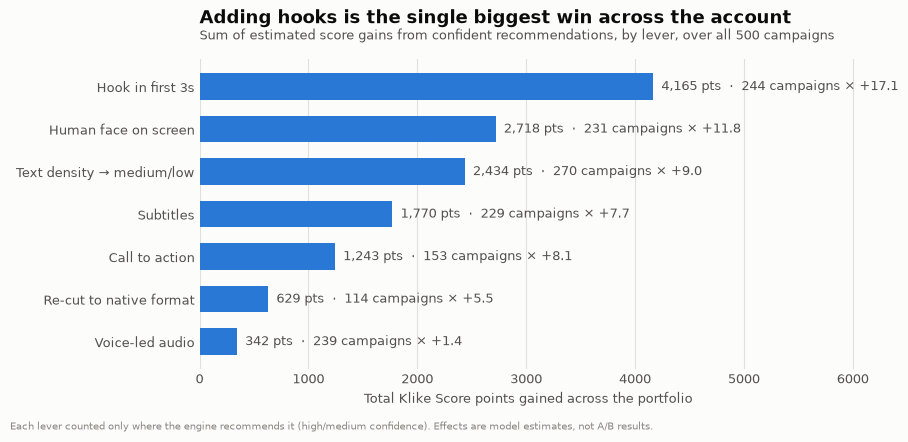

In [11]:
confident = portfolio[portfolio["confidence"].isin(["high", "medium"])]
# Duration is recommended for CTR, not score (9 campaigns): it has no place on a score chart.
opportunity = (confident[confident["lever"] != "video_duration_s"].groupby("lever")
               .agg(campaigns=("campaign_id", "nunique"), mean_gain=("score_gain", "mean"), total=("score_gain", "sum"))
               .sort_values("total"))
names = {"text_density": "Text density → medium/low", "format": "Re-cut to native format",
         "music_voice_ratio": "Voice-led audio", "video_duration_s": "Duration (CTR only)"}

# CHART 2 - one measure, one hue: total points on the table per lever.
figure, ax = new_chart((9, 4.4))
positions = np.arange(len(opportunity))
ax.barh(positions, opportunity["total"], height=0.62, color=BLUE, zorder=3)
for position, (lever, row) in zip(positions, opportunity.iterrows()):
    ax.annotate(f"{row['total']:,.0f} pts  ·  {int(row['campaigns'])} campaigns × {row['mean_gain']:+.1f}",
                xy=(row["total"], position), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK_SOFT)
ax.set_yticks(positions, [names.get(l, LABELS.get(l, l)) for l in opportunity.index])
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_xlim(0, opportunity["total"].max() * 1.45)
ax.set_xlabel("Total Klike Score points gained across the portfolio", color=INK_SOFT, fontsize=9.5)
finish(figure, ax,
       "Adding hooks is the single biggest win across the account",
       "Sum of estimated score gains from confident recommendations, by lever, over all 500 campaigns",
       "Each lever counted only where the engine recommends it (high/medium confidence). Effects are model estimates, not A/B results.",
       name="03_portfolio_opportunity")

In [12]:
# Opportunity by platform: the same levers, a different mix.
mix = (confident.groupby(["platform", "lever"])["score_gain"].sum().unstack(fill_value=0)
       .rename(columns=lambda l: names.get(l, LABELS.get(l, l))))
mix.div(mix.sum(axis=1), axis=0).round(2).T

platform,LinkedIn,Meta,TikTok
lever,,,
Re-cut to native format,0.10,0.06,0.01
Call to action,0.08,0.08,0.11
Human face on screen,0.18,0.22,0.20
Hook in first 3s,0.29,0.30,0.34
Subtitles,0.10,0.14,0.15
Voice-led audio,0.03,0.03,0.02
Text density → medium/low,0.22,0.18,0.17
Duration (CTR only),0.00,0.00,0.00


---
# 5. Limits — what the engine can and cannot claim

- **Associations, not causal effects.** Every number comes from observational campaign data, adjusted
  for the confounders the dataset records (platform, category, objective, age, retargeting). An
  unrecorded confounder — e.g. bigger brands both using hooks and getting better CTR — would inflate
  an estimate. That is why each recommendation carries an interval, why the wording is "associated
  with", and why the natural next step is to validate the top levers with A/B tests (Part 4).
- **Effects are combined additively.** The potential score assumes the gains stack. Part 2 found no
  interactions between levers, which supports it, but stacking six changes moves a creative far from
  anything the data has seen; the potential is an upper-bound guide, capped at 100.
- **Score gains are the same everywhere except format; metric lifts are platform-specific.** That is a
  finding (Part 2: no lever × platform interaction on the score), not a simplification.
- **Engagement assumes basis points** (Part 1). Thirteen values below 1 bp look like a placeholder and
  are excluded from the engagement model.
- **LinkedIn is thin** (83 campaigns, 11 vertical). Its platform-specific estimates are shrunk toward
  the pooled ones and have the widest intervals.